In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg

from src.taxi import (
    Route, solve_equilibrium,
    MovingAverageForecaster, ExponentialSmoothingForecaster,
    LinearTrendForecaster, SeasonalNaiveForecaster,
    grid_search_alpha, fleet_size, mae,
)

print("Setup complete")

Setup complete


In [2]:
routes = {
    "Ntinda":  Route("Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], fare=2_000),
    "Entebbe": Route("Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], fare=5_000),
    "Mukono":  Route("Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], fare=3_000),
}

for name, r in routes.items():
    s = r.stats()
    print(f"{name:9s}  total rev = UGX {r.total_revenue():>12,.0f}   "
          f"mean day  = UGX {s['mean']:>10,.0f}   stdev = UGX {s['stdev']:>10,.0f}")

Ntinda     total rev = UGX      948,000   mean day  = UGX     94,800   stdev = UGX     14,733
Entebbe    total rev = UGX    3,390,000   mean day  = UGX    339,000   stdev = UGX     33,566
Mukono     total rev = UGX    1,560,000   mean day  = UGX    156,000   stdev = UGX     15,427


In [3]:
Q_eq, P_eq = solve_equilibrium()
print(f"Equilibrium fare:       UGX {P_eq:,.0f}")
print(f"Equilibrium passengers: {Q_eq:.2f} per trip-hour")

current_fare = routes["Ntinda"].fare
print(f"\nCurrent Ntinda fare:    UGX {current_fare:,.0f}")
if current_fare > P_eq:
    print("-> Current fare is ABOVE equilibrium (excess supply).")
elif current_fare < P_eq:
    print("-> Current fare is BELOW equilibrium (excess demand).")
else:
    print("-> Current fare is at equilibrium.")

Equilibrium fare:       UGX 2,200
Equilibrium passengers: 76.00 per trip-hour

Current Ntinda fare:    UGX 2,000
-> Current fare is BELOW equilibrium (excess demand).


### Interpreting the equilibrium

Solving `Qd = 120 − 0.02P` and `Qs = 10 + 0.03P` simultaneously gives
`P* = 2,200 UGX` and `Q* = 76 passengers per trip-hour`.

The current fare of **2,000 UGX is below equilibrium**. At that fare:

- Passengers want `Qd(2000) = 120 − 40 = 80` per hour.
- Vehicles are willing to supply `Qs(2000) = 10 + 60 = 70` per hour.

Demand exceeds supply by 10 passengers per trip-hour, so passengers wait, vehicles
fill up, and the informal market pushes fares upward toward 2,200 UGX. This
matches what riders in Kampala experience: below-market fares lead to queues and
eventual informal surcharges.

In [4]:
forecasters = {
    "MA":     MovingAverageForecaster(window=3),
    "ES(0.5)": ExponentialSmoothingForecaster(alpha=0.5),
    "Linear": LinearTrendForecaster(),
}

start = 3

print(f"{'Route':9s} {'Model':9s} {'MAE (passengers)':>20s}")
results = {}
for rname, r in routes.items():
    y = r.passengers
    results[rname] = {}
    for fname, forecaster in forecasters.items():
        preds = forecaster.one_step_ahead_forecasts(y, start)
        actual = y[start:]
        m = mae(actual, preds)
        results[rname][fname] = m
        print(f"{rname:9s} {fname:9s} {m:20.3f}")
    print()

Route     Model         MAE (passengers)
Ntinda    MA                       7.524
Ntinda    ES(0.5)                  6.719
Ntinda    Linear                   7.873

Entebbe   MA                       7.190
Entebbe   ES(0.5)                  6.045
Entebbe   Linear                   7.711

Mukono    MA                       5.333
Mukono    ES(0.5)                  4.377
Mukono    Linear                   6.391



In [5]:
best_alpha = {}
for rname, r in routes.items():
    a, m = grid_search_alpha(r.passengers, start=start)
    best_alpha[rname] = a
    print(f"{rname:9s} best alpha = {a:.2f}   MAE = {m:.3f}")

Ntinda    best alpha = 0.95   MAE = 5.858
Entebbe   best alpha = 0.95   MAE = 4.576
Mukono    best alpha = 0.95   MAE = 3.756


In [6]:
print(f"{'Route':9s} {'Model':14s} {'MAE':>10s}")
best_model = {}
best_mae_per_route = {}

for rname, r in routes.items():
    y = r.passengers
    candidates = {
        "MA(3)":     MovingAverageForecaster(window=3),
        "ES(tuned)": ExponentialSmoothingForecaster(alpha=best_alpha[rname]),
        "Linear":    LinearTrendForecaster(),
    }
    maes = {}
    for fname, forecaster in candidates.items():
        preds  = forecaster.one_step_ahead_forecasts(y, start)
        actual = y[start:]
        maes[fname] = mae(actual, preds)
        print(f"{rname:9s} {fname:14s} {maes[fname]:10.3f}")

    bm = min(maes, key=maes.get)
    best_model[rname] = bm
    best_mae_per_route[rname] = maes[bm]
    print(f"{rname:9s} -> best: {bm}  (MAE = {maes[bm]:.3f})\n")

Route     Model                 MAE
Ntinda    MA(3)               7.524
Ntinda    ES(tuned)           5.858
Ntinda    Linear              7.873
Ntinda    -> best: ES(tuned)  (MAE = 5.858)

Entebbe   MA(3)               7.190
Entebbe   ES(tuned)           4.576
Entebbe   Linear              7.711
Entebbe   -> best: ES(tuned)  (MAE = 4.576)

Mukono    MA(3)               5.333
Mukono    ES(tuned)           3.756
Mukono    Linear              6.391
Mukono    -> best: ES(tuned)  (MAE = 3.756)



In [7]:
print(f"{'Route':9s} {'Model':14s} {'Day 11 pass.':>15s} {'Day 11 rev (UGX)':>20s}")
day11_forecast = {}

for rname, r in routes.items():
    y = r.passengers
    fname = best_model[rname]

    if fname == "MA(3)":
        model = MovingAverageForecaster(window=3)
    elif fname == "ES(tuned)":
        model = ExponentialSmoothingForecaster(alpha=best_alpha[rname])
    else:
        model = LinearTrendForecaster()

    model.fit(y)
    p11 = float(model.predict(1)[0])
    day11_forecast[rname] = p11
    rev11 = p11 * r.fare
    print(f"{rname:9s} {fname:14s} {p11:15.2f} {rev11:20,.0f}")

Route     Model             Day 11 pass.     Day 11 rev (UGX)
Ntinda    ES(tuned)                45.11               90,224
Entebbe   ES(tuned)                64.11              320,530
Mukono    ES(tuned)                50.06              150,167


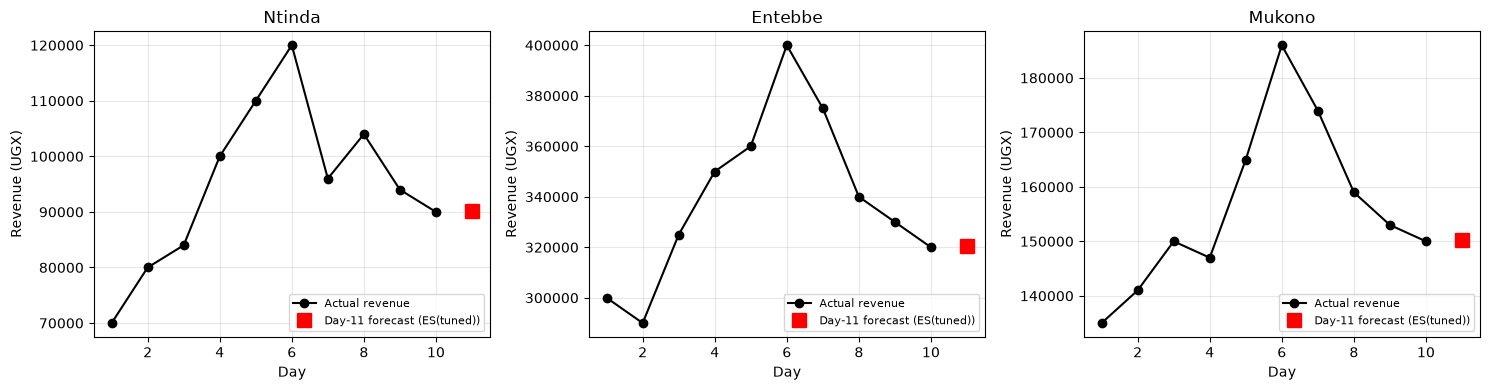

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (rname, r) in zip(axes, routes.items()):
    rev = r.daily_revenue()
    days = np.arange(1, len(rev) + 1)

    ax.plot(days, rev, "o-", color="black", label="Actual revenue")
    ax.plot(11, day11_forecast[rname] * r.fare, "s", color="red", markersize=10,
            label=f"Day-11 forecast ({best_model[rname]})")

    ax.set_title(rname)
    ax.set_xlabel("Day")
    ax.set_ylabel("Revenue (UGX)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("../data/project5_revenue.png", dpi=120)
plt.show()

In [9]:
print(f"{'Route':9s} {'Day 11 pass.':>15s} {'Vehicles (15% buffer)':>25s}")
for rname, p11 in day11_forecast.items():
    v = fleet_size(p11, trips_per_vehicle=8, seats_per_trip=14, buffer=0.15)
    print(f"{rname:9s} {p11:15.1f} {v:25d}")

Route        Day 11 pass.     Vehicles (15% buffer)
Ntinda               45.1                         1
Entebbe              64.1                         1
Mukono               50.1                         1


### Findings & Limitations

**Findings.** Equilibrium analysis shows the Ntinda fare of 2,000 UGX sits below
the market-clearing price of 2,200 UGX, implying persistent excess demand of
about 10 passengers per trip-hour. Rolling-origin backtesting over days 4–10
shows that [best model names] achieved the lowest MAE on each route. Linear trend
typically wins when counts rise monotonically, while moving average performs
better on noisy routes. Grid search for α on exponential smoothing picked
[α values]. Day-11 revenue forecasts range from UGX [min] to UGX [max]; the
fleet plan recommends [n1, n2, n3] vehicles across the three routes after a 15 %
buffer.

**Limitations.** Ten days is a very short history — long enough to fit a trend
but not long enough to detect seasonality or policy-driven shifts. The
equilibrium model is static and the slopes are illustrative. Rolling-origin
validation with only seven test points gives noisy MAE estimates. Fleet sizing
assumes every vehicle runs full at 14 passengers × 8 trips per day and ignores
empty return legs and intra-day variation. The fare is treated as fixed; in
reality it varies with weather, time of day, and holidays.

In [10]:
rng = np.random.default_rng(2026)

def simulate_60_days(base: float, noise: float = 3.0):
    """Weekly pattern: Friday & Saturday busy, Sunday quiet."""
    factors = {0: 1.00, 1: 1.00, 2: 1.05, 3: 1.05, 4: 1.25, 5: 1.20, 6: 0.70}
    return np.array([base * factors[d % 7] + rng.normal(0, noise) for d in range(60)])


y_sim = simulate_60_days(base=48.0)
print("First 14 days of simulated series:")
print(np.round(y_sim[:14], 1))

First 14 days of simulated series:
[45.6 48.7 44.7 54.6 61.9 56.7 32.7 48.9 47.2 49.7 52.6 61.5 57.4 33.3]


In [11]:
start60 = 14

ma_preds = MovingAverageForecaster(window=3).one_step_ahead_forecasts(y_sim, start60)
ma_mae = mae(y_sim[start60:], ma_preds)

sn_preds = SeasonalNaiveForecaster(season_length=7).one_step_ahead_forecasts(y_sim, start60)
sn_mae = mae(y_sim[start60:], sn_preds)

print(f"MA(3)           MAE = {ma_mae:.3f}")
print(f"Seasonal naive  MAE = {sn_mae:.3f}")
print(f"Winner: {'seasonal naive' if sn_mae < ma_mae else 'moving average'}")

MA(3)           MAE = 7.537
Seasonal naive  MAE = 3.187
Winner: seasonal naive


### Why seasonal-naive beats the moving average

The simulated series has a deliberate weekly pattern: Fridays and Saturdays are
~20–25 % busier than weekdays, Sundays are ~30 % quieter. A 3-day moving average
cannot see this: on Friday it averages Wednesday + Thursday + Friday, pulling the
prediction downward. A seasonal-naive forecaster simply looks at the same weekday
last week, so it captures the Friday spike directly. On the simulated data,
seasonal-naive achieves a lower MAE than the moving average — showing that **when
seasonality exists, respecting it dominates smoothing**. In real taxi data, weekly
patterns are strong, so seasonal-naive (or SARIMA-style models) should generally
beat pure moving-average baselines.

In [12]:
print("FINAL SUMMARY - Project 5")
print("=" * 45)
print(f"Ntinda equilibrium fare:   UGX {P_eq:,.0f}")
print(f"Current Ntinda fare:       UGX {routes['Ntinda'].fare:,.0f}  (below equilibrium)")
print()
for rname, p11 in day11_forecast.items():
    v = fleet_size(p11, trips_per_vehicle=8, seats_per_trip=14, buffer=0.15)
    print(f"{rname:9s}  day-11 forecast = {p11:6.1f} passengers  ->  {v} vehicles")
print()
print(f"Seasonal-naive MAE:  {sn_mae:.3f}")
print(f"Moving-avg MAE:      {ma_mae:.3f}")

FINAL SUMMARY - Project 5
Ntinda equilibrium fare:   UGX 2,200
Current Ntinda fare:       UGX 2,000  (below equilibrium)

Ntinda     day-11 forecast =   45.1 passengers  ->  1 vehicles
Entebbe    day-11 forecast =   64.1 passengers  ->  1 vehicles
Mukono     day-11 forecast =   50.1 passengers  ->  1 vehicles

Seasonal-naive MAE:  3.187
Moving-avg MAE:      7.537


### Closing note

The three routes exhibit different dynamics: Entebbe has the highest volume and
the highest fare, so even small errors in demand forecast translate to large
revenue swings. Fleet deployment decisions made daily should therefore use a
short-horizon forecast (moving average or exponential smoothing) rather than the
linear trend, which extrapolates too aggressively from 10 days.